# InceptionV3_HD - Hair Disease Classification (10 classes)

**Run the cells strictly from top to bottom, one at a time, and read each output before moving on.**

| Part | Cells | What it produces |
|---|---|---|
| A. Setup | 1-5 | GPU check, Drive, config, seed, data copied to Colab disk |
| B. Data verification | 6-12 | Class counts, leakage check between splits, sample images |
| C. Model sanity checks | 13-16 | Proof that the model and pipeline work before real training |
| D. Training | 17-24 | Phase 1 (head only) and Phase 2 (fine-tuning), curves, best checkpoint |
| E. Final test evaluation | 25-32 | Metrics, confusion matrix, 95% CI, error analysis (**run once**) |
| F. Save | 33 | Summary of the whole experiment |

Every run writes to its own folder `results/<RUN_NAME>/`, so nothing is overwritten.
To report mean +- std, repeat the whole notebook with `SEED = 42, 123, 2024`.

## A. Setup

### Cell 1 - Imports, library versions, GPU
Expected: a GPU name (e.g. Tesla T4). If the list is empty: Runtime > Change runtime type > T4 GPU.

In [1]:
import os, sys, json, time, random, zipfile, subprocess, platform, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, cohen_kappa_score, roc_auc_score, classification_report,
                             confusion_matrix)
from PIL import Image

print("Python     :", platform.python_version())
print("TensorFlow :", tf.__version__)
print("Keras      :", tf.keras.__version__)
print("NumPy      :", np.__version__)
print("scikit-learn:", sklearn.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs       :", gpus)
assert gpus, "No GPU found. Runtime > Change runtime type > T4 GPU, then restart."
print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout)

Python     : 3.13.15
TensorFlow : 2.21.0
Keras      : 3.13.2
NumPy      : 2.1.3
scikit-learn: 1.6.1
GPUs       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-d8c37b36-f6cd-421f-b97f-b60d4a10cd59)



### Cell 2 - Mount Google Drive
A pop-up will ask for permission. Click Allow.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### Cell 3 - Experiment configuration
**Edit `DRIVE_DIR` only** (the Drive folder that contains `data_processed/` and `results/`).
All hyper-parameters live here, so they are recorded with the results.
Tip: in the Colab Files panel, right-click your project folder > Copy path.

In [3]:
# ------------------------------------------------------------- EDIT THIS LINE
DRIVE_DIR = "/content/drive/MyDrive/Hair-Disease-Research"
# -------------------------------------------------------------------------

SEED = 42
ZIP_PATH = f"{DRIVE_DIR}/data_processed/dataset_224_v3.zip"
RESULTS_ROOT = f"{DRIVE_DIR}/results"
DATA_DIR = "/content/dataset_224_v3"       # local copy on Colab disk (fast)

IMG_SIZE = (224, 224)         # size of the stored images (data pipeline)
INPUT_SIZE = (299, 299)       # InceptionV3 native size; images are resized INSIDE the model
MODEL_NAME = "inceptionv3"
BATCH = 32

# Phase 1: train the new classification head, backbone frozen
EPOCHS_P1 = 10
LR_P1 = 1e-3
ES_PATIENCE_P1 = 4

# Phase 2: fine-tune the top of the backbone (BatchNorm layers stay frozen)
EPOCHS_P2 = 25
LR_P2 = 1e-5
FINE_TUNE_AT = 249            # InceptionV3 (311 layers): unfreeze the last 2 inception blocks (Keras docs)
ES_PATIENCE_P2 = 6

DROPOUT = 0.3
AUG = {"flip": "horizontal", "rotation": 0.05, "zoom": 0.1, "contrast": 0.1}

RUN_NAME = f"{MODEL_NAME}_seed{SEED}_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = f"{RESULTS_ROOT}/{RUN_NAME}"

assert os.path.exists(ZIP_PATH), f"Zip not found: {ZIP_PATH}\nCheck DRIVE_DIR and the folder structure."
os.makedirs(RUN_DIR, exist_ok=True)

CONFIG = {k: v for k, v in globals().items()
          if k.isupper() and isinstance(v, (int, float, str, tuple, dict))}
json.dump(CONFIG, open(f"{RUN_DIR}/config.json", "w"), indent=2, default=str)
print("Run folder:", RUN_DIR)
print(json.dumps(CONFIG, indent=2, default=str))

Run folder: /content/drive/MyDrive/Hair-Disease-Research/results/inceptionv3_seed42_20261023_161640
{
  "DRIVE_DIR": "/content/drive/MyDrive/Hair-Disease-Research",
  "SEED": 42,
  "ZIP_PATH": "/content/drive/MyDrive/Hair-Disease-Research/data_processed/dataset_224_v3.zip",
  "RESULTS_ROOT": "/content/drive/MyDrive/Hair-Disease-Research/results",
  "DATA_DIR": "/content/dataset_224_v3",
  "IMG_SIZE": [
    224,
    224
  ],
  "INPUT_SIZE": [
    299,
    299
  ],
  "MODEL_NAME": "inceptionv3",
  "BATCH": 32,
  "EPOCHS_P1": 10,
  "LR_P1": 0.001,
  "ES_PATIENCE_P1": 4,
  "EPOCHS_P2": 25,
  "LR_P2": 1e-05,
  "FINE_TUNE_AT": 249,
  "ES_PATIENCE_P2": 6,
  "DROPOUT": 0.3,
  "AUG": {
    "flip": "horizontal",
    "rotation": 0.05,
    "zoom": 0.1,
    "contrast": 0.1
  },
  "RUN_NAME": "inceptionv3_seed42_20261023_161640",
  "RUN_DIR": "/content/drive/MyDrive/Hair-Disease-Research/results/inceptionv3_seed42_20261023_161640"
}


### Cell 4 - Fix random seeds
Seeds make the run repeatable as far as possible. GPU kernels are not perfectly deterministic,
so tiny differences between runs with the same seed are normal. Mention this in the report.

In [4]:
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Seed set to", SEED)

Seed set to 42


### Cell 5 - Copy and unzip the dataset to the Colab disk
Expected: `['train', 'val', 'test']`. Takes 1-3 minutes the first time.

In [5]:
if not os.path.exists(DATA_DIR):
    t0 = time.time()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall("/content")
    print(f"Unzipped in {time.time() - t0:.0f}s")
print(sorted(d for d in os.listdir(DATA_DIR) if not d.startswith(".")))

Unzipped in 8s
['test', 'train', 'val']


## B. Data verification

### Cell 6 - Class names and image counts per split
Expected: 10 classes, identical in all three splits; about 70/15/15 split
(train 8328, val 1785, test 1783, total 11896).

In [6]:
SPLITS = ["train", "val", "test"]

def list_classes(split):
    p = f"{DATA_DIR}/{split}"
    return sorted(d for d in os.listdir(p) if os.path.isdir(f"{p}/{d}") and not d.startswith("."))

cls_by_split = {s: list_classes(s) for s in SPLITS}
assert cls_by_split["train"] == cls_by_split["val"] == cls_by_split["test"], "Class folders differ between splits!"

def n_images(split, c):
    return len([f for f in os.listdir(f"{DATA_DIR}/{split}/{c}") if f.lower().endswith((".jpg", ".jpeg", ".png"))])

counts = pd.DataFrame({s: {c: n_images(s, c) for c in cls_by_split[s]} for s in SPLITS})
counts.loc["TOTAL"] = counts.sum()
counts["all"] = counts[SPLITS].sum(axis=1)
print(counts)
counts.to_csv(f"{RUN_DIR}/class_counts.csv")

                       train   val  test    all
Alopecia Areata          835   179   179   1193
Contact Dermatitis       834   179   179   1192
Folliculitis             834   179   178   1191
Head Lice                836   179   179   1194
Lichen Planus            836   179   179   1194
Male Pattern Baldness    776   166   166   1108
Psoriasis                787   169   169   1125
Seborrheic Dermatitis    807   173   173   1153
Telogen Effluvium        801   172   171   1144
Tinea Capitis            839   180   180   1199
TOTAL                   8185  1755  1753  11693


### Cell 7 - Class distribution plot
Check that no class is far smaller than the others.

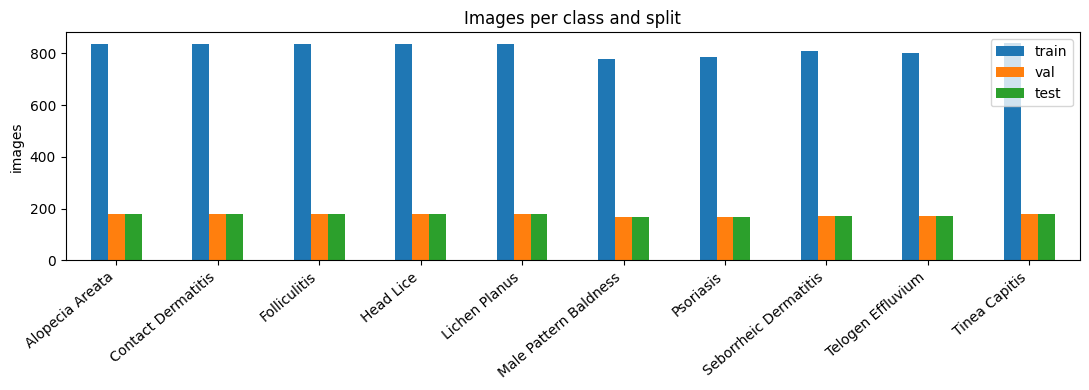

                       train    val   test
Alopecia Areata        0.102  0.102  0.102
Contact Dermatitis     0.102  0.102  0.102
Folliculitis           0.102  0.102  0.102
Head Lice              0.102  0.102  0.102
Lichen Planus          0.102  0.102  0.102
Male Pattern Baldness  0.095  0.095  0.095
Psoriasis              0.096  0.096  0.096
Seborrheic Dermatitis  0.099  0.099  0.099
Telogen Effluvium      0.098  0.098  0.098
Tinea Capitis          0.103  0.103  0.103


In [7]:
c2 = counts.drop(index="TOTAL")[SPLITS]
ax = c2.plot(kind="bar", figsize=(11, 4))
ax.set_ylabel("images"); ax.set_title("Images per class and split")
plt.xticks(rotation=40, ha="right"); plt.tight_layout()
plt.savefig(f"{RUN_DIR}/class_distribution.png", dpi=150); plt.show()
print((c2 / c2.sum()).round(3))

### Cell 8 - Load the three datasets
Expected output: `Found N files belonging to 10 classes` for each split.

In [8]:
def load_split(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f"{DATA_DIR}/{split}", image_size=IMG_SIZE, batch_size=BATCH,
        label_mode="int", shuffle=shuffle, seed=SEED)

train_raw = load_split("train", True)
val_raw = load_split("val", False)
test_raw = load_split("test", False)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
assert class_names == val_raw.class_names == test_raw.class_names
print("Classes:", class_names)

# file lists (val/test are not shuffled, so file order == prediction order)
train_files, val_files, test_files = train_raw.file_paths, val_raw.file_paths, test_raw.file_paths
print(len(train_files), len(val_files), len(test_files))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.prefetch(AUTOTUNE)
val_ds = val_raw.prefetch(AUTOTUNE)
test_ds = test_raw.prefetch(AUTOTUNE)
json.dump(class_names, open(f"{RUN_DIR}/class_names.json", "w"))

Found 8185 files belonging to 10 classes.
Found 1755 files belonging to 10 classes.
Found 1753 files belonging to 10 classes.
Classes: ['Alopecia Areata', 'Contact Dermatitis', 'Folliculitis', 'Head Lice', 'Lichen Planus', 'Male Pattern Baldness', 'Psoriasis', 'Seborrheic Dermatitis', 'Telogen Effluvium', 'Tinea Capitis']
8185 1755 1753


### Cell 9 - Leakage check (1/3): install and compute perceptual hashes
(Two code cells below: first the install, then the hashing. Run both.)
This is an **independent re-check after the re-split**. Hashes are computed on the final 224x224 images.

In [9]:
%pip install -q imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 22.4 MB/s eta 0:00:00


In [10]:
import imagehash
from PIL import ImageOps

def phash_int(im):
    bits = imagehash.phash(im).hash.flatten()
    return np.uint64(int("".join("1" if b else "0" for b in bits), 2))

def hashes(files, flip=False):
    out = np.zeros(len(files), dtype=np.uint64)
    for i, f in enumerate(files):
        with Image.open(f) as im:
            im = im.convert("RGB")
            out[i] = phash_int(ImageOps.mirror(im) if flip else im)
    return out

t0 = time.time()
H = {"train": hashes(train_files), "val": hashes(val_files), "test": hashes(test_files)}
H_flip = {"val": hashes(val_files, flip=True), "test": hashes(test_files, flip=True)}
print(f"Hashing done in {time.time() - t0:.0f}s")

Hashing done in 31s


### Cell 10 - Leakage check (2/3): compare splits
Counts image pairs from different splits whose pHash distance is small (<=2 = nearly identical, <=4 = very similar).
The `flipped` rows compare mirrored val/test images with train, to catch horizontally flipped copies.

**Interpretation:** ideally 0 or very few. Because the hash is now computed on padded images, numbers differ
from the earlier audit. A handful of pairs at distance 3-4 can be visually similar but different patients/photos;
look at a few before deciding anything.

In [11]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def cross_pairs(a, b, thr):
    pairs = []
    for s in range(0, len(a), 256):
        x = a[s:s + 256, None] ^ b[None, :]
        d = POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(axis=-1)
        for i, j in np.argwhere(d <= thr):
            pairs.append((s + int(i), int(j), int(d[i, j])))
    return pairs

rows, found = [], {}
for name, a, b in [("train vs val", H["train"], H["val"]),
                   ("train vs test", H["train"], H["test"]),
                   ("val vs test", H["val"], H["test"]),
                   ("train vs val (flipped)", H["train"], H_flip["val"]),
                   ("train vs test (flipped)", H["train"], H_flip["test"])]:
    p = cross_pairs(a, b, 4)
    found[name] = p
    rows.append({"comparison": name,
                 "pairs dist<=2": sum(1 for _, _, d in p if d <= 2),
                 "pairs dist<=4": len(p)})
leak_df = pd.DataFrame(rows)
print(leak_df.to_string(index=False))
leak_df.to_csv(f"{RUN_DIR}/leakage_check.csv", index=False)

             comparison  pairs dist<=2  pairs dist<=4
           train vs val              0              0
          train vs test              0              0
            val vs test              0              0
 train vs val (flipped)              0              0
train vs test (flipped)              0              0


### Cell 11 - Leakage check (3/3): look at the closest pairs between train and test
If pairs exist, this shows the 6 closest ones. Same lesion/photo in both => leakage.

In [12]:
p = sorted(found["train vs test"], key=lambda t: t[2])[:6]
if not p:
    print("No train/test pair with pHash distance <= 4.")
else:
    fig, ax = plt.subplots(len(p), 2, figsize=(5, 2.6 * len(p)))
    ax = np.atleast_2d(ax)
    for r, (i, j, d) in enumerate(p):
        for c, f in enumerate([train_files[i], test_files[j]]):
            ax[r, c].imshow(Image.open(f)); ax[r, c].axis("off")
            ax[r, c].set_title(("train" if c == 0 else "test") + f" | d={d}\n" + os.path.basename(f), fontsize=7)
    plt.tight_layout(); plt.savefig(f"{RUN_DIR}/closest_train_test_pairs.png", dpi=130); plt.show()

No train/test pair with pHash distance <= 4.


### Cell 12 - Look at some training images
Check that images look correct and that labels match the pictures.

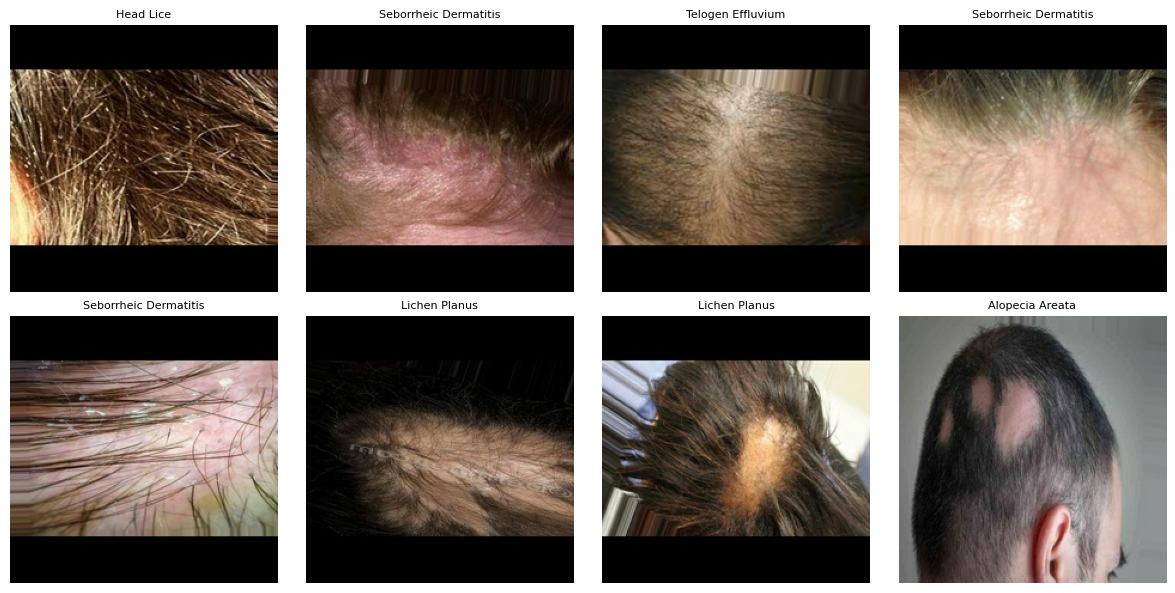

In [13]:
plt.figure(figsize=(12, 6))
for images, labels in train_raw.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=8); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/sample_train_images.png", dpi=130); plt.show()

## C. Model definition and sanity checks

### Cell 13 - Augmentation layers (training only) and a visual check
Augmentation is part of the model, and Keras switches it **off** automatically for validation and test.
Left: original. Others: random augmentations of the same image. Make sure they still look like plausible scalp photos.

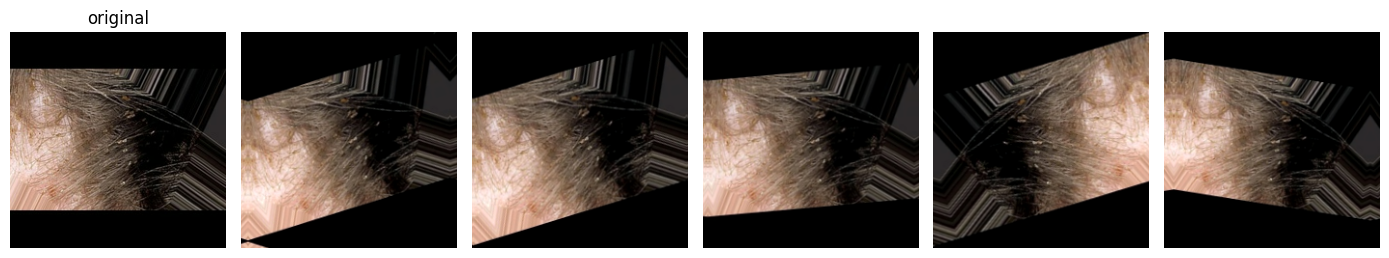

In [14]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(AUG["flip"]),
    tf.keras.layers.RandomRotation(AUG["rotation"]),
    tf.keras.layers.RandomZoom(AUG["zoom"]),
    tf.keras.layers.RandomContrast(AUG["contrast"]),
], name="augmentation")

img = next(iter(train_raw.take(1)))[0][:1]
plt.figure(figsize=(14, 3))
plt.subplot(1, 6, 1); plt.imshow(img[0].numpy().astype("uint8")); plt.title("original"); plt.axis("off")
for k in range(5):
    plt.subplot(1, 6, k + 2)
    plt.imshow(np.clip(augment(img, training=True)[0].numpy(), 0, 255).astype("uint8")); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/augmentation_check.png", dpi=130); plt.show()

### Cell 14 - Model builder
InceptionV3 (ImageNet weights) + global average pooling + dropout + softmax layer.
`Rescaling(1/127.5, offset=-1)` is identical to `inception_v3.preprocess_input` (pixels to [-1, 1]).
Images are stored at 224x224 and resized to 299x299 inside the model (the size InceptionV3 was designed for).
This keeps the data identical to the MobileNetV2 experiment, so the comparison is fair.

In [15]:
def build_model():
    base = tf.keras.applications.InceptionV3(input_shape=INPUT_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    x = augment(inputs)
    x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(x)       # == inception_v3.preprocess_input
    x = tf.keras.layers.Resizing(INPUT_SIZE[0], INPUT_SIZE[1])(x)  # 224 -> 299 (native size of InceptionV3)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(DROPOUT)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs), base

def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("builder ready")

builder ready


### Cell 15 - Sanity check 1: initial loss
A randomly initialised 10-class head should give loss close to ln(10) = 2.30 and accuracy near 10%.
Much higher or lower values mean something is wrong (labels, preprocessing, loss function).

In [16]:
xv, yv = next(iter(val_raw.take(1)))
m0, _ = build_model(); compile_model(m0, LR_P1)
loss0, acc0 = m0.evaluate(xv, yv, verbose=0)
print(f"initial loss = {loss0:.3f}   (expected about {np.log(NUM_CLASSES):.3f})")
print(f"initial acc  = {acc0:.3f}   (expected about {1 / NUM_CLASSES:.3f})")
del m0

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
initial loss = 2.423   (expected about 2.303)
initial acc  = 0.031   (expected about 0.100)


### Cell 16 - Sanity check 2: can the model overfit one small batch?
Train a throw-away model on a single batch of 32 images. Training accuracy should rise far above chance
(typically > 0.9). If it cannot, the pipeline has a bug. This model is discarded.

In [17]:
xb, yb = next(iter(train_raw.take(1)))
m1, _ = build_model(); compile_model(m1, LR_P1)
h = m1.fit(xb, yb, epochs=40, verbose=0)
print(f"loss  {h.history['loss'][0]:.3f} -> {h.history['loss'][-1]:.3f}")
print(f"acc   {h.history['accuracy'][0]:.3f} -> {h.history['accuracy'][-1]:.3f}")
del m1
tf.keras.backend.clear_session()

loss  2.871 -> 0.320
acc   0.094 -> 0.906


## D. Training

### Cell 17 - Build the real model
Expected: ~21.8M total parameters, of which only 20,490 are trainable (the new head: 2048 x 10 + 10).

In [18]:
tf.keras.utils.set_random_seed(SEED)
model, base = build_model()
compile_model(model, LR_P1)
model.summary(show_trainable=True)
n_train = int(sum(np.prod(w.shape) for w in model.trainable_weights))
n_total = int(model.count_params())
print(f"Trainable params: {n_train:,} / {n_total:,}")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ rescaling (Rescaling)       │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resizing (Resizing)         │ (None, 299, 299, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ inception_v3 (Functional)   │ (None, 8, 8, 2048)    │ 21,802,784 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 10)            │     20,490 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 21,823,274 (83.25 MB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

Trainable params: 20,490 / 21,823,274


### Cell 18 - Callbacks
Early stopping and checkpoints monitor **validation loss** (never the test set).

In [19]:
CKPT_P1 = f"{RUN_DIR}/ckpt_phase1.keras"
CKPT_P2 = f"{RUN_DIR}/ckpt_phase2.keras"

def make_callbacks(ckpt, patience, log_name):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, verbose=0),
        tf.keras.callbacks.CSVLogger(f"{RUN_DIR}/{log_name}.csv"),
    ]
print("ok")

ok


### Cell 19 - Phase 1: train the classification head (backbone frozen)
Watch `val_loss`: it should decrease in the first epochs.

In [20]:
t0 = time.time()
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_P1,
               callbacks=make_callbacks(CKPT_P1, ES_PATIENCE_P1, "log_phase1"))
print(f"Phase 1 finished in {(time.time() - t0) / 60:.1f} min")

Epoch 1/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 219ms/step - accuracy: 0.6033 - loss: 1.2127 - val_accuracy: 0.6940 - val_loss: 0.9481 - learning_rate: 0.0010
Epoch 2/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 54s 212ms/step - accuracy: 0.8081 - loss: 0.6405 - val_accuracy: 0.7664 - val_loss: 0.7093 - learning_rate: 0.0010
Epoch 3/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 53s 206ms/step - accuracy: 0.8593 - loss: 0.4755 - val_accuracy: 0.8131 - val_loss: 0.5918 - learning_rate: 0.0010
Epoch 4/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 54s 211ms/step - accuracy: 0.8911 - loss: 0.3905 - val_accuracy: 0.8165 - val_loss: 0.5430 - learning_rate: 0.0010
Epoch 5/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 54s 212ms/step - accuracy: 0.8963 - loss: 0.3482 - val_accuracy: 0.8598 - val_loss: 0.4466 - learning_rate: 0.0010
Epoch 6/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 81s 207ms/step - accuracy: 0.9101 - loss: 0.3082 - val_accuracy: 0.8632 - val_loss: 0.4126 - learning_rate: 0.0010
Epoch 7/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 54s 212ms/step - accuracy: 0.9

### Cell 20 - Phase 1 result

In [21]:
d1 = pd.DataFrame(h1.history)
best1 = d1["val_loss"].idxmin()
print(f"Best epoch (phase 1): {best1 + 1}  val_loss={d1.loc[best1, 'val_loss']:.4f}  val_acc={d1.loc[best1, 'val_accuracy']:.4f}")
print(d1.round(4).to_string())

Best epoch (phase 1): 10  val_loss=0.3058  val_acc=0.9083
   accuracy    loss  val_accuracy  val_loss  learning_rate
0    0.6033  1.2127        0.6940    0.9481          0.001
1    0.8081  0.6405        0.7664    0.7093          0.001
2    0.8593  0.4755        0.8131    0.5918          0.001
3    0.8911  0.3905        0.8165    0.5430          0.001
4    0.8963  0.3482        0.8598    0.4466          0.001
5    0.9101  0.3082        0.8632    0.4126          0.001
6    0.9136  0.2844        0.8872    0.3815          0.001
7    0.9207  0.2635        0.8849    0.3663          0.001
8    0.9252  0.2470        0.8946    0.3287          0.001
9    0.9282  0.2354        0.9083    0.3058          0.001


### Cell 21 - Phase 2 setup: unfreeze the top of InceptionV3
Layers before `FINE_TUNE_AT` (249 of 311) stay frozen, so the last two inception blocks are trained. BatchNorm layers always stay frozen (standard practice for small datasets).
Learning rate drops to `LR_P2`. The model is recompiled (required after changing `trainable`).

In [22]:
base.trainable = True
for layer in base.layers[:FINE_TUNE_AT]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

compile_model(model, LR_P2)
n_train2 = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print(f"Trainable params now: {n_train2:,} / {n_total:,}")

Trainable params now: 11,128,842 / 21,823,274


### Cell 22 - Phase 2: fine-tuning
This phase starts from the best phase-1 weights (restored by early stopping).

In [23]:
t0 = time.time()
h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_P2,
               callbacks=make_callbacks(CKPT_P2, ES_PATIENCE_P2, "log_phase2"))
print(f"Phase 2 finished in {(time.time() - t0) / 60:.1f} min")

Epoch 1/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 76s 260ms/step - accuracy: 0.9587 - loss: 0.1373 - val_accuracy: 0.9476 - val_loss: 0.1595 - learning_rate: 1.0000e-05
Epoch 2/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 62s 243ms/step - accuracy: 0.9831 - loss: 0.0624 - val_accuracy: 0.9698 - val_loss: 0.1005 - learning_rate: 1.0000e-05
Epoch 3/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 64s 250ms/step - accuracy: 0.9890 - loss: 0.0354 - val_accuracy: 0.9721 - val_loss: 0.0894 - learning_rate: 1.0000e-05
Epoch 4/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 245ms/step - accuracy: 0.9913 - loss: 0.0278 - val_accuracy: 0.9818 - val_loss: 0.0601 - learning_rate: 1.0000e-05
Epoch 5/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 244ms/step - accuracy: 0.9963 - loss: 0.0155 - val_accuracy: 0.9823 - val_loss: 0.0562 - learning_rate: 1.0000e-05
Epoch 6/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 244ms/step - accuracy: 0.9973 - loss: 0.0113 - val_accuracy: 0.9840 - val_loss: 0.0473 - learning_rate: 1.0000e-05
Epoch 7/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 64s 25

### Cell 23 - Training curves (both phases)
Look for overfitting: train accuracy far above val accuracy and val loss rising.

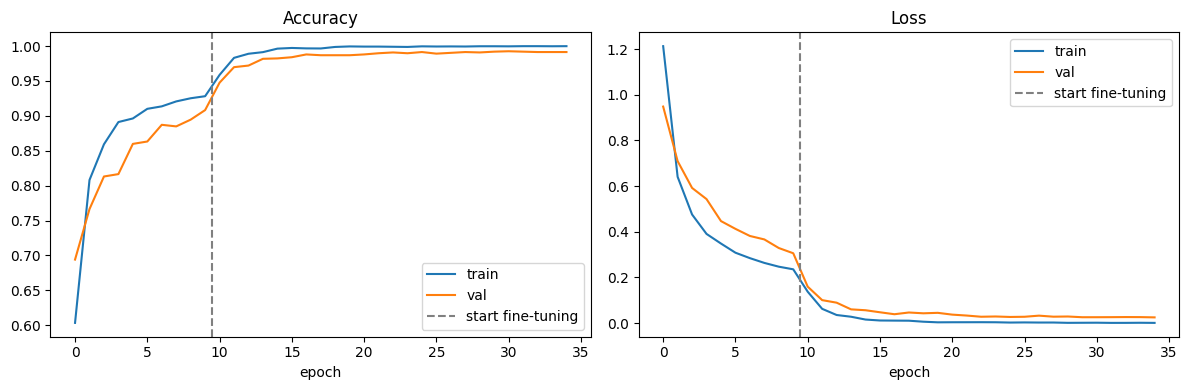

In [24]:
d2 = pd.DataFrame(h2.history)
hist = pd.concat([d1.assign(phase=1), d2.assign(phase=2)], ignore_index=True)
hist.to_csv(f"{RUN_DIR}/history_all.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, k, t in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    a.plot(hist[k], label="train"); a.plot(hist["val_" + k], label="val")
    a.axvline(len(d1) - 0.5, color="gray", linestyle="--", label="start fine-tuning")
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/training_curves.png", dpi=150); plt.show()

### Cell 24 - Choose the final model using VALIDATION loss only
Fine-tuning does not always help. We evaluate both checkpoints on the validation set and keep the better one.

In [25]:
res = {}
for name, path in [("phase1", CKPT_P1), ("phase2", CKPT_P2)]:
    if os.path.exists(path):
        m = tf.keras.models.load_model(path)
        l, a = m.evaluate(val_ds, verbose=0)
        res[name] = {"val_loss": float(l), "val_acc": float(a), "path": path}
        print(f"{name}: val_loss={l:.4f}  val_acc={a:.4f}")
best_name = min(res, key=lambda k: res[k]["val_loss"])
print("Selected:", best_name)
final_model = tf.keras.models.load_model(res[best_name]["path"])
json.dump({"selected": best_name, **res}, open(f"{RUN_DIR}/model_selection.json", "w"), indent=2)

phase1: val_loss=0.3058  val_acc=0.9083
phase2: val_loss=0.0250  val_acc=0.9915
Selected: phase2


## E. Final evaluation on the TEST set
**Run Cells 25-32 once.** Do not change any hyper-parameter after seeing test results,
otherwise the test set stops being independent. If you must change something, repeat the experiment
under a new RUN_NAME and say so in the report.

### Cell 25 - Predictions on the test set

In [26]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = final_model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)
assert len(y_true) == len(y_pred) == len(test_files)

pred_df = pd.DataFrame({
    "file": [os.path.relpath(f, DATA_DIR) for f in test_files],
    "true": [class_names[i] for i in y_true],
    "pred": [class_names[i] for i in y_pred],
    "confidence": y_prob.max(axis=1),
    **{f"p_{c}": y_prob[:, i] for i, c in enumerate(class_names)},
})
pred_df.to_csv(f"{RUN_DIR}/test_predictions.csv", index=False)
print(pred_df.head())

                                            file             true  \
0  test/Alopecia Areata/alopecia_areata_0001.jpg  Alopecia Areata   
1  test/Alopecia Areata/alopecia_areata_0008.jpg  Alopecia Areata   
2  test/Alopecia Areata/alopecia_areata_0009.jpg  Alopecia Areata   
3  test/Alopecia Areata/alopecia_areata_0023.jpg  Alopecia Areata   
4  test/Alopecia Areata/alopecia_areata_0029.jpg  Alopecia Areata   

              pred  confidence  p_Alopecia Areata  p_Contact Dermatitis  \
0  Alopecia Areata    0.999817           0.999817          3.310154e-15   
1  Alopecia Areata    0.999985           0.999985          3.686416e-13   
2  Alopecia Areata    1.000000           1.000000          2.183615e-17   
3  Alopecia Areata    1.000000           1.000000          2.181211e-15   
4  Alopecia Areata    0.865790           0.865790          7.831449e-07   

   p_Folliculitis   p_Head Lice  p_Lichen Planus  p_Male Pattern Baldness  \
0    4.703756e-10  6.749352e-15     3.292293e-10         

### Cell 26 - Overall metrics

In [27]:
acc = accuracy_score(y_true, y_pred)
bal = balanced_accuracy_score(y_true, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
f1w = f1_score(y_true, y_pred, average="weighted", zero_division=0)
kappa = cohen_kappa_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")

metrics = {"accuracy": acc, "balanced_accuracy": bal, "macro_precision": p, "macro_recall": r,
           "macro_f1": f1, "weighted_f1": f1w, "cohen_kappa": kappa, "macro_auc_ovr": auc}
metrics = {k: float(v) for k, v in metrics.items()}
for k, v in metrics.items():
    print(f"{k:18s}: {v:.4f}")
json.dump(metrics, open(f"{RUN_DIR}/test_metrics.json", "w"), indent=2)

accuracy          : 0.9920
balanced_accuracy : 0.9919
macro_precision   : 0.9920
macro_recall      : 0.9919
macro_f1          : 0.9919
weighted_f1       : 0.9920
cohen_kappa       : 0.9911
macro_auc_ovr     : 1.0000


### Cell 27 - Per-class precision / recall / F1
Look for weak classes, then confirm in the confusion matrix.

In [28]:
report = classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0)
print(report)
open(f"{RUN_DIR}/classification_report.txt", "w").write(report)
pd.DataFrame(classification_report(y_true, y_pred, target_names=class_names, output_dict=True,
                                   zero_division=0)).T.to_csv(f"{RUN_DIR}/classification_report.csv")

                       precision    recall  f1-score   support

      Alopecia Areata     1.0000    0.9944    0.9972       179
   Contact Dermatitis     0.9944    1.0000    0.9972       179
         Folliculitis     1.0000    0.9944    0.9972       178
            Head Lice     0.9835    1.0000    0.9917       179
        Lichen Planus     1.0000    0.9944    0.9972       179
Male Pattern Baldness     1.0000    1.0000    1.0000       166
            Psoriasis     0.9879    0.9645    0.9760       169
Seborrheic Dermatitis     0.9826    0.9769    0.9797       173
    Telogen Effluvium     0.9827    0.9942    0.9884       171
        Tinea Capitis     0.9890    1.0000    0.9945       180

             accuracy                         0.9920      1753
            macro avg     0.9920    0.9919    0.9919      1753
         weighted avg     0.9920    0.9920    0.9920      1753



### Cell 28 - Confusion matrices (counts and row-normalised)

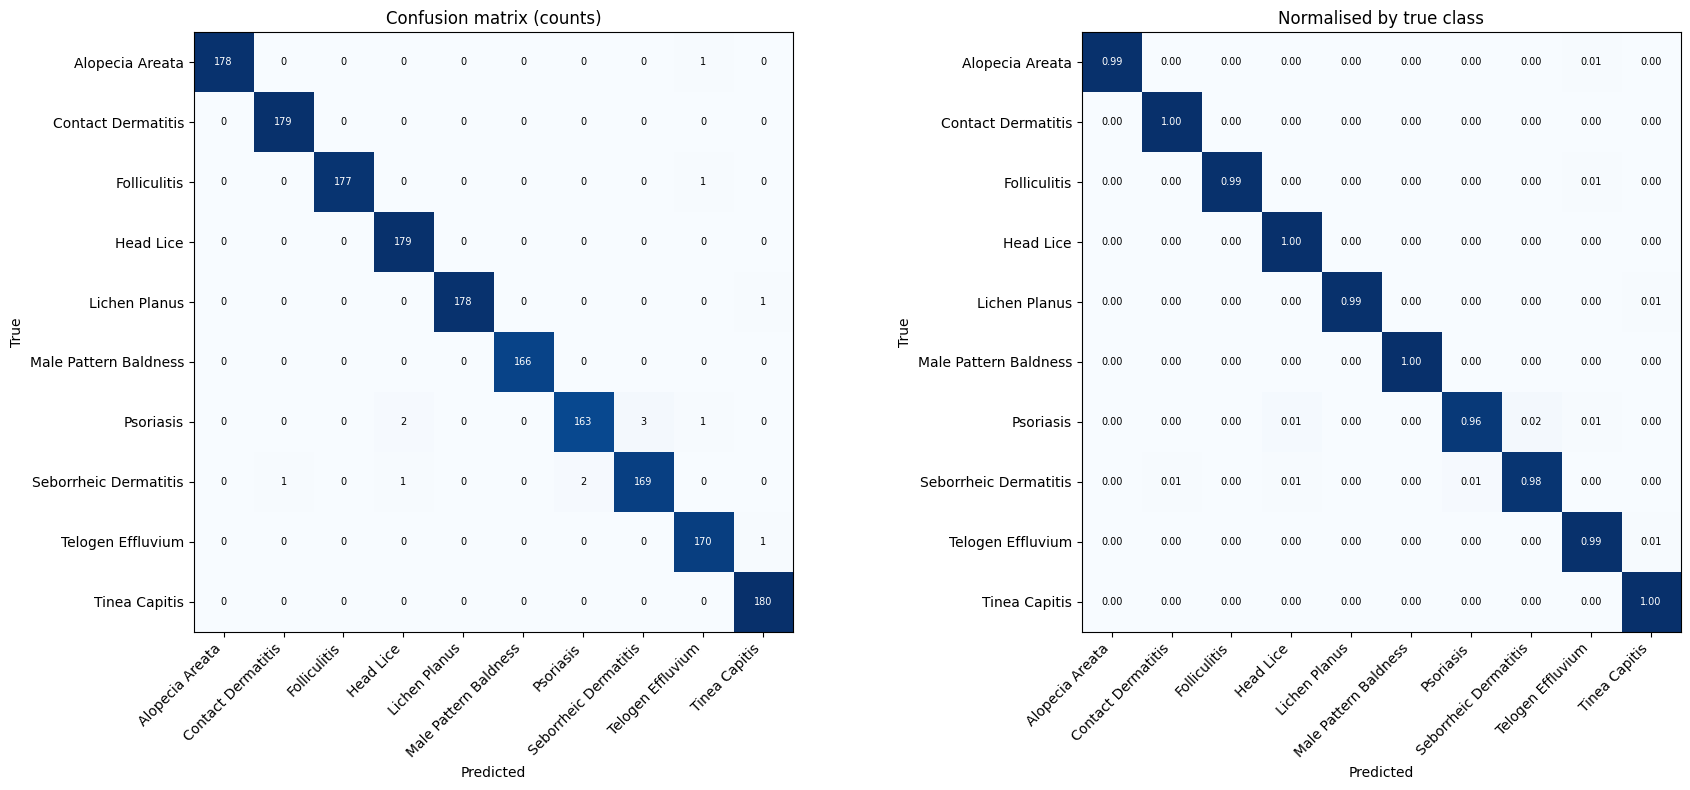

In [29]:
cm = confusion_matrix(y_true, y_pred)
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a, M, title, fmt in [(ax[0], cm, "Confusion matrix (counts)", "d"), (ax[1], cmn, "Normalised by true class", ".2f")]:
    im = a.imshow(M, cmap="Blues")
    a.set_xticks(range(NUM_CLASSES)); a.set_yticks(range(NUM_CLASSES))
    a.set_xticklabels(class_names, rotation=45, ha="right"); a.set_yticklabels(class_names)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            a.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=7,
                   color="white" if M[i, j] > M.max() / 2 else "black")
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(title)
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confusion_matrix.png", dpi=150); plt.show()
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(f"{RUN_DIR}/confusion_matrix.csv")

### Cell 29 - 95% bootstrap confidence intervals
Resamples the test set 1000 times. Report as `accuracy = 0.xx (95% CI lo-hi)`.

In [30]:
rng = np.random.default_rng(SEED)
n = len(y_true)
accs, f1s = [], []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    accs.append((y_true[idx] == y_pred[idx]).mean())
    f1s.append(f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0))
ci = {"accuracy_ci95": [float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))],
      "macro_f1_ci95": [float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))]}
print(f"Accuracy : {acc:.4f}  95% CI [{ci['accuracy_ci95'][0]:.4f}, {ci['accuracy_ci95'][1]:.4f}]")
print(f"Macro-F1 : {f1:.4f}  95% CI [{ci['macro_f1_ci95'][0]:.4f}, {ci['macro_f1_ci95'][1]:.4f}]")
json.dump(ci, open(f"{RUN_DIR}/test_bootstrap_ci.json", "w"), indent=2)

Accuracy : 0.9920  95% CI [0.9880, 0.9960]
Macro-F1 : 0.9919  95% CI [0.9877, 0.9960]


### Cell 30 - Most confused class pairs

In [31]:
off = [(class_names[i], class_names[j], int(cm[i, j])) for i in range(NUM_CLASSES)
       for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
conf_df = pd.DataFrame(sorted(off, key=lambda t: -t[2]), columns=["true", "predicted_as", "count"])
print(conf_df.head(10).to_string(index=False))
conf_df.to_csv(f"{RUN_DIR}/confused_pairs.csv", index=False)

                 true          predicted_as  count
            Psoriasis Seborrheic Dermatitis      3
            Psoriasis             Head Lice      2
Seborrheic Dermatitis             Psoriasis      2
      Alopecia Areata     Telogen Effluvium      1
         Folliculitis     Telogen Effluvium      1
        Lichen Planus         Tinea Capitis      1
            Psoriasis     Telogen Effluvium      1
Seborrheic Dermatitis    Contact Dermatitis      1
Seborrheic Dermatitis             Head Lice      1
    Telogen Effluvium         Tinea Capitis      1


### Cell 31 - Confident mistakes (error analysis)
The 12 test images the model got wrong with the highest confidence. Check them by eye:
label noise, hard images, or a real model weakness? This is a good discussion point for the thesis.

14 wrong predictions out of 1753


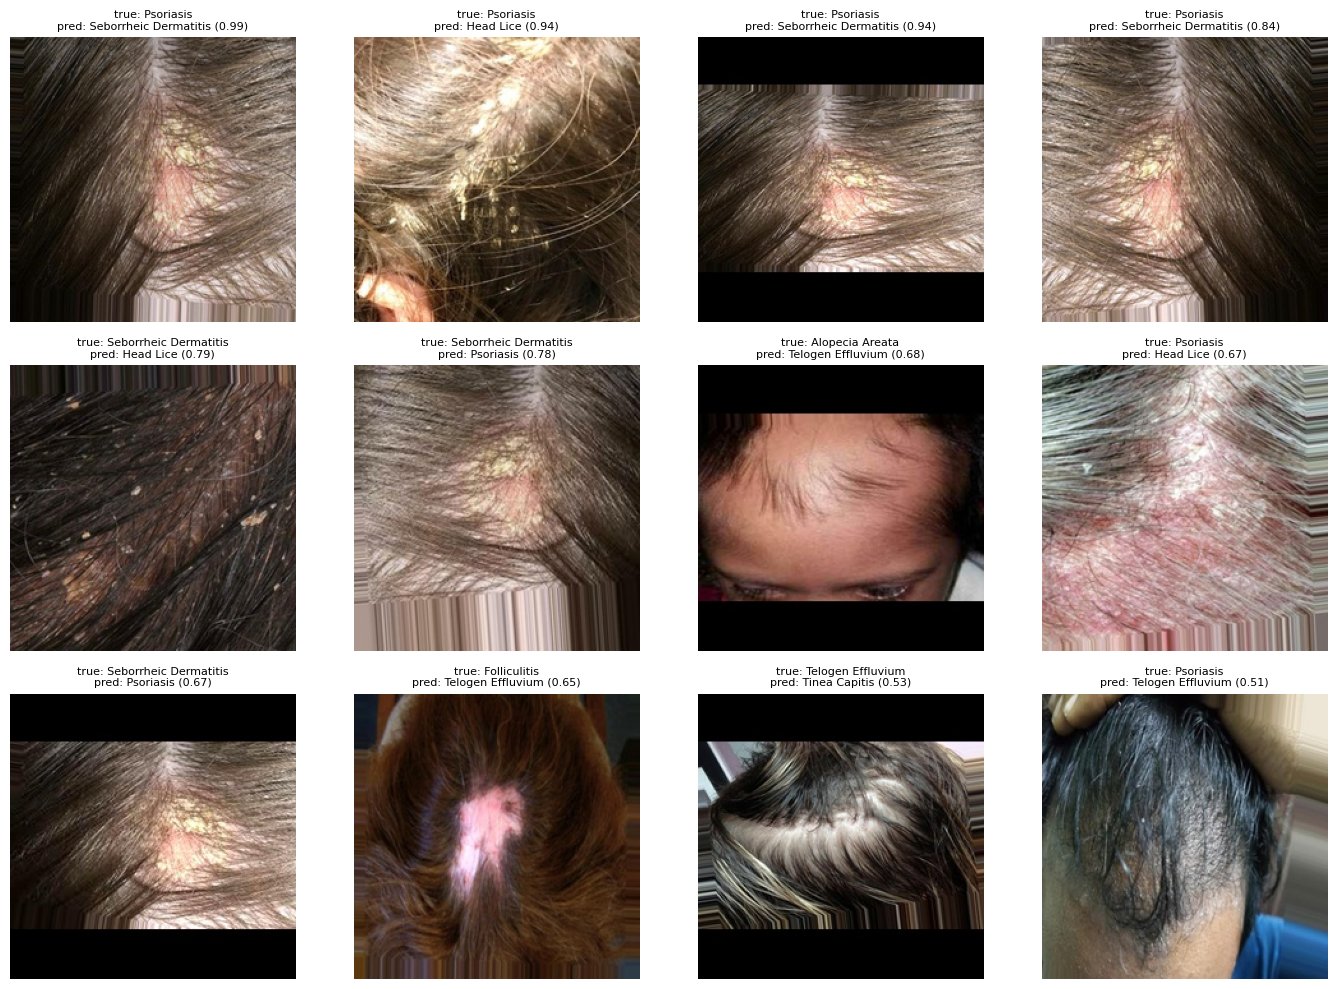

In [32]:
wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} wrong predictions out of {len(y_true)}")
if len(wrong):
    top = wrong[np.argsort(-y_prob.max(axis=1)[wrong])][:12]
    fig, ax = plt.subplots(3, 4, figsize=(14, 10))
    for a, i in zip(ax.ravel(), top):
        a.imshow(Image.open(test_files[i])); a.axis("off")
        a.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=8)
    for a in ax.ravel()[len(top):]:
        a.axis("off")
    plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confident_errors.png", dpi=130); plt.show()

### Cell 32 - Confidence vs correctness
A well-behaved model is more confident when it is right.

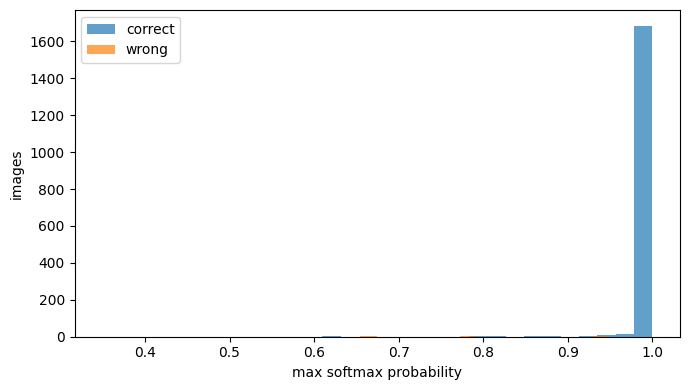

mean confidence  correct: 0.995   wrong: 0.706


In [33]:
conf = y_prob.max(axis=1)
plt.figure(figsize=(7, 4))
plt.hist(conf[y_true == y_pred], bins=30, alpha=0.7, label="correct")
plt.hist(conf[y_true != y_pred], bins=30, alpha=0.7, label="wrong")
plt.xlabel("max softmax probability"); plt.ylabel("images"); plt.legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confidence_hist.png", dpi=130); plt.show()
print(f"mean confidence  correct: {conf[y_true == y_pred].mean():.3f}   wrong: {conf[y_true != y_pred].mean() if (y_true != y_pred).any() else float('nan'):.3f}")

## F. Save everything

### Cell 33 - Save the final model and an experiment summary

In [34]:
final_model.save(f"{RUN_DIR}/final_model.keras")
summary = {
    "run_name": RUN_NAME,
    "seed": SEED,
    "selected_checkpoint": best_name,
    "n_images": {"train": len(train_files), "val": len(val_files), "test": len(test_files)},
    "val": {k: res[best_name][k] for k in ["val_loss", "val_acc"]},
    "test_metrics": metrics,
    "test_bootstrap_ci": ci,
    "tf_version": tf.__version__,
}
json.dump(summary, open(f"{RUN_DIR}/experiment_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))
print("\nAll files saved in:", RUN_DIR)
print(sorted(os.listdir(RUN_DIR)))

{
  "run_name": "inceptionv3_seed42_20261023_161640",
  "seed": 42,
  "selected_checkpoint": "phase2",
  "n_images": {
    "train": 8185,
    "val": 1755,
    "test": 1753
  },
  "val": {
    "val_loss": 0.024952750653028488,
    "val_acc": 0.9914529919624329
  },
  "test_metrics": {
    "accuracy": 0.9920136908157444,
    "balanced_accuracy": 0.9918736539034875,
    "macro_precision": 0.992006780392316,
    "macro_recall": 0.9918736539034875,
    "macro_f1": 0.9919090373331333,
    "weighted_f1": 0.9919958654935374,
    "cohen_kappa": 0.9911254660649061,
    "macro_auc_ovr": 0.9999705342235835
  },
  "test_bootstrap_ci": {
    "accuracy_ci95": [
      0.9880205362236166,
      0.9960068454078722
    ],
    "macro_f1_ci95": [
      0.9877281316195378,
      0.9960032045906818
    ]
  },
  "tf_version": "2.21.0"
}

All files saved in: /content/drive/MyDrive/Hair-Disease-Research/results/inceptionv3_seed42_20261023_161640
['augmentation_check.png', 'ckpt_phase1.keras', 'ckpt_phase2.keras